# Day 14

In [1]:
from sklearn.metrics import mean_squared_error,root_mean_squared_error,mean_absolute_error,classification_report
import pandas as pd, numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import graphviz
from sklearn.tree import export_graphviz

In [2]:
df = pd.read_csv('churn.csv')

In [3]:
df

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48
Exited,10000.0,2.037000e-01,0.402769,0.00,0.00,0.000000e+00,0.000000e+00,1.00


<Axes: ylabel='CreditScore'>

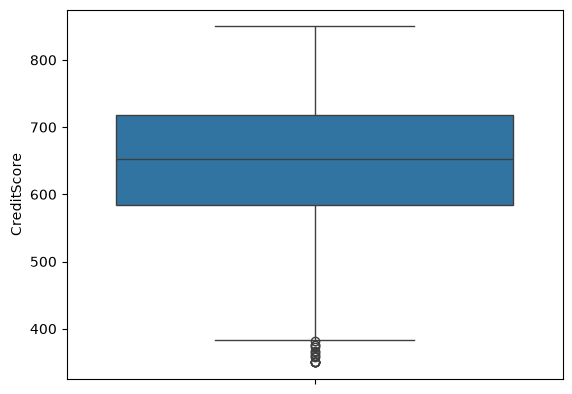

In [5]:
sns.boxplot(df.CreditScore)

In [6]:
x = df.iloc[:,2:-1]
x

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10
...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77
9997,709,France,Female,36,7,0.00,1,0,1,42085.58
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52


In [7]:
x1 = pd.get_dummies(x, columns=['Geography','Gender'],drop_first=True)

In [8]:
y = df['Exited']
y

0       1
1       0
2       1
3       0
4       0
       ..
9995    0
9996    0
9997    1
9998    1
9999    0
Name: Exited, Length: 10000, dtype: int64

In [9]:
xtrain,xtest,ytrain,ytest = train_test_split(x1,y,test_size=0.2,random_state=7,stratify=y)

In [10]:
lg = LogisticRegression(solver='newton-cholesky',max_iter=40000)

In [11]:
ytrain

4858    0
1733    0
7073    0
9864    0
438     0
       ..
2235    1
7931    0
6695    0
6572    0
2170    0
Name: Exited, Length: 8000, dtype: int64

In [12]:
ytest

8443    0
3573    0
7047    0
1535    0
9475    0
       ..
8302    0
695     0
8338    0
288     0
6091    0
Name: Exited, Length: 2000, dtype: int64

In [13]:
model = lg.fit(xtrain,ytrain)

In [14]:
pred = model.predict(xtest)

In [15]:
pd.crosstab(ytest,pred)

col_0,0,1
Exited,,
0,1533,60
1,315,92


---

## Decision Trees

In [ ]:
dtree = DecisionTreeClassifier(max_depth=4)

In [42]:
model2 = dtree.fit(xtrain,ytrain)

In [43]:
dot_data = export_graphviz(model2,out_file=None,feature_names=x1.columns,class_names=[str(x) for x in model2.classes_],filled=True,rounded=True)
dot_data = dot_data.replace(
    "digraph Tree {",
    'digraph Tree {\nsize="18,18";\nratio="compress";'
)

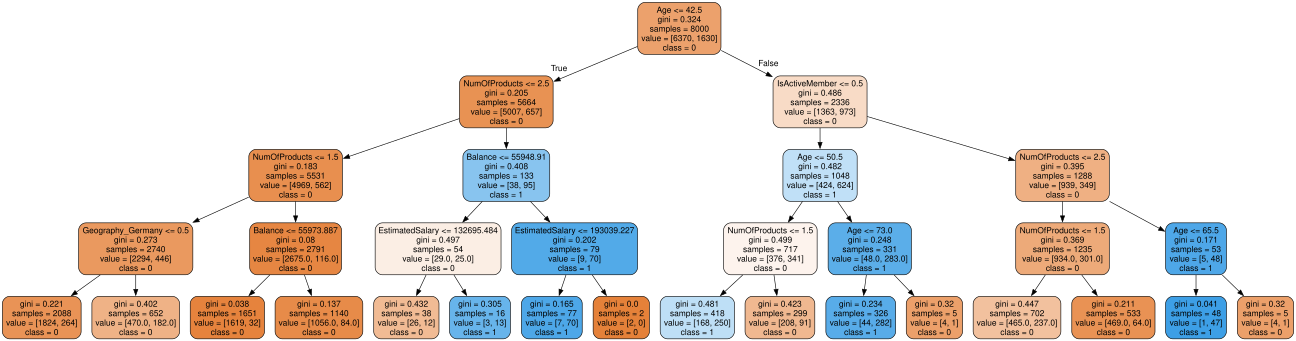

In [44]:
graphviz.Source(dot_data)

In [45]:
pred2 = model2.predict(xtest)

In [46]:
mean_squared_error(ytest,pred2)

0.1455

In [47]:
pd.crosstab(ytest,pred2)

col_0,0,1
Exited,,
0,1535,58
1,233,174


In [48]:
print(classification_report(ytest,pred2))

              precision    recall  f1-score   support

           0       0.87      0.96      0.91      1593
           1       0.75      0.43      0.54       407

    accuracy                           0.85      2000
   macro avg       0.81      0.70      0.73      2000
weighted avg       0.84      0.85      0.84      2000

